# Notebook 01 — Exploratory Data Analysis (EDA)

**Project:** deepbook-flowcast — predicting short-term price moves on DeepBook, Sui's on-chain order book.

**What we are predicting:** where the SUI/USDC mid-price will be **10 seconds from now**:
`UP (+1)`, `FLAT (0)` or `DOWN (−1)`. That makes this a **classification** problem (3 classes).

**Data (built earlier in the pipeline):**
- `data/processed/features/` — one row per second, 37 features computed from the rebuilt order book, trades, order events and Binance prices. Every feature only looks **backwards** in time.
- `data/processed/labels/` — the target `label_10s` (and the raw 10-second return `ret_10s`, in basis points; 1 bp = 0.01%).

**Split (by time, not random):** train = Aug 2025, validation = Sep 2025, test = Oct 2025 (+ Jul–Sep 2026).
This notebook only explores **training data (August)**, with September shown for comparison. October stays untouched so we never peek at the test set.

## 1. Imports

In [1]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.preprocessing import StandardScaler
from pathlib import Path

pd.set_option("display.max_columns", 50)
plt.rcParams["figure.dpi"] = 110

## 2. Load the data

The features are stored one file per day. We load **August 2025 (train)** and **September 2025 (validation, for comparison only)** for the SUI_USDC pool.

We keep **one row every 10 seconds**. Our target looks 10 seconds ahead, so neighbouring seconds share almost the same future and are near-duplicates. Taking every 10th row gives non-overlapping windows, which keeps histograms, correlations and p-values honest.

In [2]:
# Read one day of features + labels, keep every 10th second
DATA = Path("../data/processed")

def load_period(start, end, stride=10):
    frames = []
    for day in pd.date_range(start, end, inclusive="left"):
        d = day.strftime("%Y-%m-%d")
        f = pd.read_parquet(DATA / "features" / "pool=SUI_USDC" / f"date={d}.parquet")
        l = pd.read_parquet(DATA / "labels" / "pool=SUI_USDC" / f"date={d}.parquet",
                            columns=["ts", "ret_10s", "label_10s"])
        df = f.merge(l, on="ts").iloc[::stride]
        df["date"] = d
        frames.append(df)
    return pd.concat(frames, ignore_index=True)

train = load_period("2025-08-01", "2025-09-01")   # training data
valid = load_period("2025-09-01", "2025-10-01")   # validation data (comparison only)
print("train:", train.shape, "  valid:", valid.shape)

train: (267840, 41)   valid: (259200, 41)


## 3. First look at the data

In [3]:
# Look at the first 5 rows
train.head()

,ts,imb_1,imb_5,imb_10,spread_bps,log_depth_bid_5,log_depth_ask_5,micro_bps,past_ret_1s,past_ret_10s,past_ret_60s,vol_60s,vol_300s,ofi_1s,ofi_5s,ofi_30s,place_imb_5s,cancel_imb_5s,place_imb_30s,cancel_imb_30s,log_events_5s,modify_share_30s,trade_imb_5s,trade_imb_30s,log_trades_30s,secs_since_trade,mm_share_30s,mm_active_10s,mm_cancel_share_30s,hour_sin,hour_cos,dow,bn_gap_bps,bn_ret_1s,bn_ret_5s,bn_ret_30s,bn_trade_imb_5s,bn_log_trades_5s,ret_10s,label_10s,date
0,1754006401000,-1.000000,-1.000000,-1.000000,NaN,0.000000,6.030685,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-1.000000,0.000000,-1.000000,0.000000,0.693147,0.0,-1.00000,-1.000000,0.693147,0.0,NaN,NaN,NaN,0.000000,1.000000,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,<NA>,2025-08-01
1,1754006411000,0.000000,0.000000,0.000000,0.276660,8.224941,8.224941,0.000000,2.075162,NaN,NaN,NaN,NaN,0.562009,1.873228,2.247088,0.083333,-0.157895,0.014925,-0.016393,3.784190,0.0,-1.00000,-0.704936,2.197225,1.0,NaN,NaN,NaN,0.000727,1.000000,4,NaN,1.383107,2.766405,NaN,1.000000,1.945910,-6.918883,-1,2025-08-01
2,1754006421000,-0.846128,-0.984621,-0.984621,6.921277,3.852273,8.691163,-2.928144,-2.491349,-6.918883,NaN,NaN,NaN,-0.624316,-1.870995,-0.208256,0.047619,0.047619,0.009901,-0.010526,3.761200,0.0,-1.00000,-0.904742,2.708050,0.0,NaN,NaN,NaN,0.001454,0.999999,4,NaN,-0.553541,-2.767400,NaN,-1.000000,2.079442,0.138425,0,2025-08-01
3,1754006431000,-0.271280,-0.032641,-0.026948,1.107389,8.160804,8.226092,-0.150206,0.000000,0.138425,NaN,NaN,NaN,0.000000,0.358027,-0.682507,-0.047619,-0.111111,-0.007092,-0.068702,3.688879,0.0,-1.00000,-0.910315,2.944439,1.0,NaN,NaN,NaN,0.002182,0.999998,4,NaN,0.000000,0.000000,NaN,0.525392,1.098612,-12.465894,-1,2025-08-01
4,1754006441000,0.720081,0.822320,0.169953,8.870163,10.947466,8.619750,3.193619,-13.711629,-12.465894,NaN,3.11764,NaN,-0.558622,0.058239,-3.080445,0.000000,0.019608,-0.034014,-0.037037,4.624973,0.0,-0.87794,-0.515149,3.526361,0.0,NaN,NaN,NaN,0.002909,0.999996,4,NaN,-8.583573,-9.967330,-14.670674,-0.429180,4.867534,7.758382,1,2025-08-01


In [4]:
# Get a brief overview of the columns
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 267840 entries, 0 to 267839
Data columns (total 41 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   ts                   267840 non-null  int64  
 1   imb_1                267840 non-null  float64
 2   imb_5                267840 non-null  float64
 3   imb_10               267840 non-null  float64
 4   spread_bps           267839 non-null  float64
 5   log_depth_bid_5      267840 non-null  float64
 6   log_depth_ask_5      267840 non-null  float64
 7   micro_bps            267839 non-null  float64
 8   past_ret_1s          267839 non-null  float64
 9   past_ret_10s         267838 non-null  float64
 10  past_ret_60s         267833 non-null  float64
 11  vol_60s              267836 non-null  float64
 12  vol_300s             267824 non-null  float64
 13  ofi_1s               267839 non-null  float64
 14  ofi_5s               267839 non-null  float64
 15  ofi_30s          

Every feature is numeric. `dow` (day of week, 0–6) is really a **category** stored as a number. `ts` is the timestamp and `date` is a helper column, so neither is a feature.

The 37 features fall into 7 groups:

| Group | # | Examples | Meaning |
|---|---|---|---|
| Book state | 7 | `imb_1`, `spread_bps`, `log_depth_bid_5` | the order book right now (`imb_1` = buy vs sell size at the best price) |
| Price | 5 | `past_ret_10s`, `vol_60s` | recent price moves and volatility |
| Order flow | 9 | `ofi_1s`, `place_imb_5s` | orders placed / cancelled in the last 1–30 s |
| Trades | 4 | `trade_imb_5s`, `secs_since_trade` | recent trades |
| Market maker | 3 | `mm_share_30s` | activity of the busiest trading bot |
| Time | 3 | `hour_sin`, `hour_cos`, `dow` | time of day / week |
| Binance | 6 | `bn_gap_bps`, `bn_ret_1s` | Binance's SUI price vs DeepBook's |

In [5]:
# Define the feature list and the target
TARGET = "label_10s"
FEATURES = [c for c in train.columns if c not in ("ts", "date", "ret_10s", TARGET)]
print(len(FEATURES), "features")

37 features


In [6]:
# Summarize the distribution of each feature
train[FEATURES].describe().T[["mean", "50%", "std", "min", "max"]].round(3)

,mean,50%,std,min,max
imb_1,0.006,0.000,0.510,-1.000,1.000
imb_5,-0.011,0.000,0.299,-1.000,0.982
imb_10,-0.001,-0.001,0.230,-1.000,0.963
spread_bps,1.218,0.561,2.755,0.239,393.505
log_depth_bid_5,9.098,9.260,0.687,0.000,12.202
log_depth_ask_5,9.120,9.265,0.703,5.767,12.106
micro_bps,0.012,0.000,1.084,-65.851,184.868
past_ret_1s,0.001,0.000,1.404,-87.383,108.617
past_ret_10s,-0.004,0.000,4.111,-101.559,145.380
past_ret_60s,-0.024,0.130,10.318,-256.418,182.997


**What stands out:**
- Most features have a median of 0 (nothing happened in that window) and a mean close to 0.
- Some have very large maximums compared with their median: `spread_bps` (median 0.56, max 393), `vol_60s` (median 0.85, max 46), `secs_since_trade` (median 4, max 266). These are long right tails, looked at in section 6.
- `modify_share_30s` is **0 in every row** (std = 0). It carries no information, so we drop it.

## 4. The target: `label_10s`

      Aug (train)  Sep (valid)
DOWN         0.33        0.254
FLAT        0.333        0.491
UP          0.338        0.255


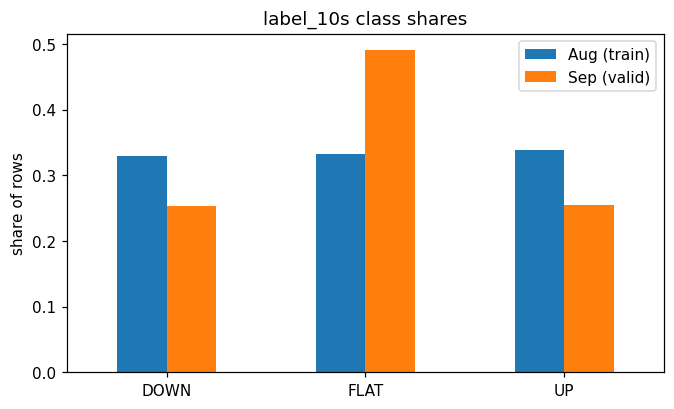

In [7]:
# Class balance in train vs validation
shares = pd.DataFrame({
    "Aug (train)": train[TARGET].value_counts(normalize=True),
    "Sep (valid)": valid[TARGET].value_counts(normalize=True),
}).reindex([-1, 0, 1])
shares.index = ["DOWN", "FLAT", "UP"]
print(shares.round(3))

shares.plot(kind="bar", rot=0, figsize=(7, 4), title="label_10s class shares")
plt.ylabel("share of rows")
plt.show()

In August the three classes are balanced (about 33% each). That is by design: "FLAT" means the price moved less than **±0.95 bps** in 10 seconds, and that threshold was chosen on August so each class gets about a third.

In September FLAT jumps to **49%**. September was a calmer month, so more 10-second windows stayed inside ±0.95 bps. The class mix shifts between months, which means:
- **accuracy alone would be misleading**: always guessing FLAT scores 49% in September.
- we will use **macro F1** (the average F1 of the three classes) and a confusion matrix, as in step 9 of the project guidelines.

## 5. Missing data

In [8]:
# Check for missing data (only columns with at least one missing value)
missing = train[FEATURES].isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
pd.DataFrame({"missing": missing, "percent": (100 * missing / len(train)).round(3)})

,missing,percent
mm_cancel_share_30s,11689,4.364
mm_share_30s,8651,3.230
mm_active_10s,8640,3.226
vol_300s,16,0.006
modify_share_30s,11,0.004
bn_gap_bps,7,0.003
past_ret_60s,7,0.003
vol_60s,4,0.001
bn_ret_30s,4,0.001
past_ret_10s,2,0.001


In [9]:
# Which days are the missing market-maker values on?
mm_cols = ["mm_share_30s", "mm_active_10s", "mm_cancel_share_30s"]
train.groupby("date")[mm_cols].apply(lambda g: g.isna().mean().mean()).sort_values(ascending=False).head(5)

date
2025-08-01    1.000000
2025-08-06    0.084491
2025-08-20    0.020563
2025-08-28    0.007485
2025-08-04    0.003048
dtype: float64

Missing values are rare and each has a reason:
- The market-maker features (`mm_*`, 3–4% missing) are **100% missing on Aug 1**. They need the *previous* day to know which bot is the busiest, and Aug 1 is the first day we collected.
- `mm_cancel_share_30s` is also missing when that bot placed or cancelled nothing in the last 30 s (dividing by zero).
- A few others (e.g. `vol_300s`) are missing for the first minutes of Aug 1, while their rolling windows fill up.

**Handling:** drop **Aug 1** (it is also the order-book warm-up day), then fill the few remaining gaps with the **training median**.

## 6. Distributions

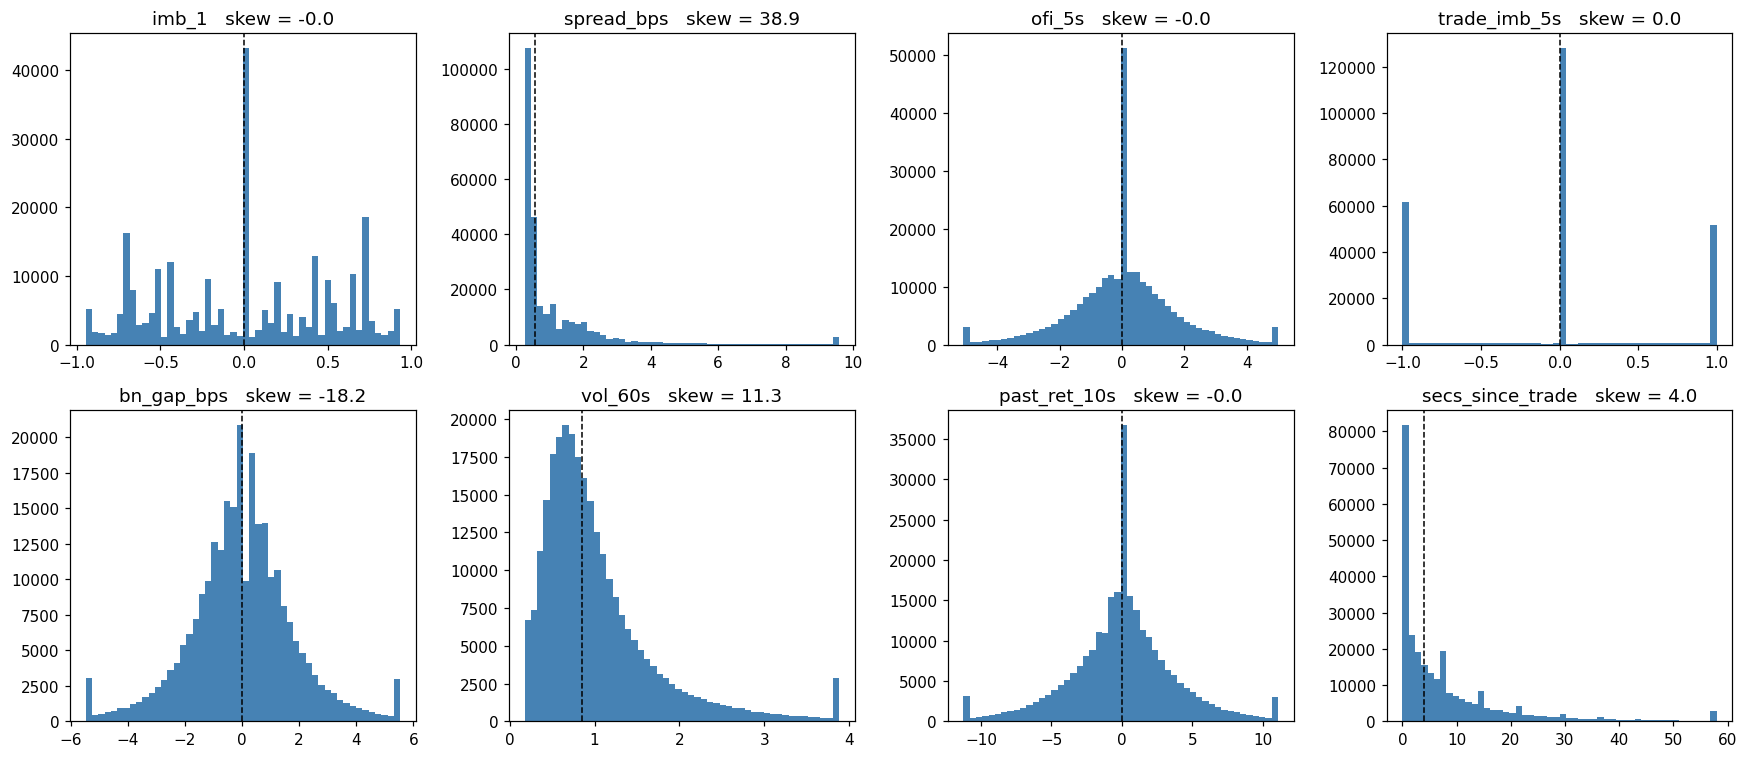

In [10]:
# Histograms of 8 key features (1st–99th percentile shown, so the shape is visible)
key = ["imb_1", "spread_bps", "ofi_5s", "trade_imb_5s",
       "bn_gap_bps", "vol_60s", "past_ret_10s", "secs_since_trade"]

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.flat, key):
    x = train[col].dropna()
    lo, hi = x.quantile([0.01, 0.99])
    ax.hist(x.clip(lo, hi), bins=50, color="steelblue")
    ax.axvline(x.median(), color="black", linestyle="--", linewidth=1)
    ax.set_title(f"{col}   skew = {x.skew():.1f}")
plt.tight_layout()
plt.show()

There are three shapes in this data:

| Shape | Features | Why |
|---|---|---|
| **Spike at 0** | `imb_1`, `ofi_5s`, `trade_imb_5s` | often nothing happened (e.g. no trades in the last 5 s gives `trade_imb_5s = 0`); `trade_imb_5s` also piles up at −1 / +1 (all sells / all buys) |
| **Bell shape** | `bn_gap_bps`, `past_ret_10s` | most values near 0, fewer further out |
| **Long right tail** | `spread_bps` (skew 38.9), `vol_60s` (11.3), `secs_since_trade` (4.0) | usually small, occasionally huge |

Skew near 0 = symmetric; above +1 = long tail to the right.

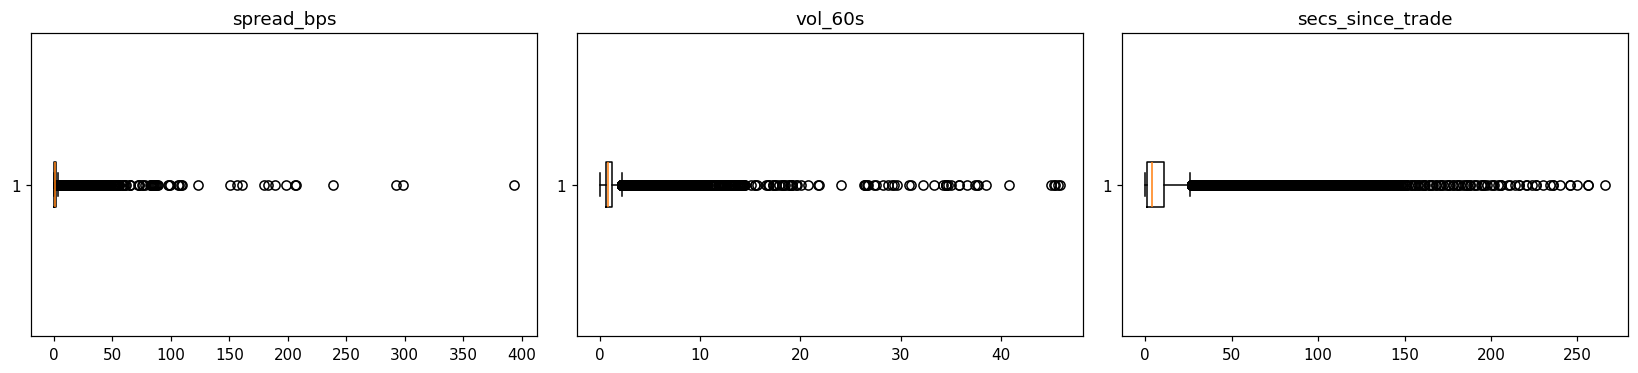

In [11]:
# Boxplots of the three long-tailed features
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, col in zip(axes, ["spread_bps", "vol_60s", "secs_since_trade"]):
    ax.boxplot(train[col].dropna(), vert=False)
    ax.set_title(col)
plt.tight_layout()
plt.show()

The boxplots show the same thing: a narrow box near 0 and a long line of points far to the right.

## 7. Outliers (IQR rule)

In [12]:
# Check for outliers with the IQR rule (same helper as Lab 12)
def iqr_bounds(series):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

rows = []
for col in ["spread_bps", "vol_60s", "secs_since_trade", "ofi_1s", "past_ret_1s", "trade_imb_5s"]:
    x = train[col].dropna()
    lo, hi = iqr_bounds(x)
    rows.append({"feature": col, "lower": round(lo, 3), "upper": round(hi, 3),
                 "share flagged": round(((x < lo) | (x > hi)).mean(), 3),
                 "share exactly 0": round((x == 0).mean(), 3)})
pd.DataFrame(rows)

,feature,lower,upper,share flagged,share exactly 0
0,spread_bps,-1.418,3.133,0.068,0.000
1,vol_60s,-0.422,2.258,0.061,0.000
2,secs_since_trade,-14.000,26.000,0.069,0.186
3,ofi_1s,-0.167,0.158,0.443,0.474
4,past_ret_1s,0.000,0.000,0.442,0.558
5,trade_imb_5s,-1.327,0.796,0.203,0.476


The IQR rule works on smooth features: for `spread_bps` it flags values above about 3 bps.

It **breaks on spiky features**. When roughly half the rows are exactly 0, Q1 and Q3 sit next to 0, the IQR is close to 0, and every ordinary non-zero value gets called an "outlier" (44% of `ofi_1s`). A rule that flags almost half the data isn't finding outliers; this data simply doesn't fit its assumption.

**Decision:**
- **Do not delete rows.** This is a time series (removing rows breaks the second-by-second sequence) and extreme moments are real market events.
- **Clip** extreme values at the 1st and 99th percentile instead, with the cutoffs computed on training data only.

## 8. Normality check (Shapiro-Wilk)

As in Lab 12, we test a few features for normality on a random sample of 5,000 rows (Shapiro-Wilk isn't meant for very large samples).

- **H0:** the feature comes from a normal distribution.
- **H1:** it does not.
- **alpha = 0.05**

In [13]:
# Shapiro-Wilk test on a 5,000-row sample
alpha = 0.05
sample = train.sample(5000, random_state=42)
for col in ["imb_1", "past_ret_10s", "bn_gap_bps", "vol_60s", "spread_bps"]:
    stat, p = stats.shapiro(sample[col].dropna())
    print(f"{col:15s}  W = {stat:.3f}   p = {p:.1e}   ->  {'not normal' if p < alpha else 'normal'}")

imb_1            W = 0.959   p = 1.9e-35   ->  not normal
past_ret_10s     W = 0.921   p = 3.1e-45   ->  not normal
bn_gap_bps       W = 0.813   p = 2.4e-60   ->  not normal
vol_60s          W = 0.472   p = 2.5e-81   ->  not normal
spread_bps       W = 0.440   p = 1.3e-82   ->  not normal


Every feature rejects H0 (p far below 0.05): **none of them is normally distributed**.

That is normal for market data, and it is **not a problem**: logistic regression does not require normal features. What it does need is covered in the next section: no huge extremes, features on similar scales, and roughly straight-line relationships.

## 9. Transformations: `log1p`, clipping, scaling

Three steps, in this order:
1. **`np.log1p(x)`** = log(1 + x). Squeezes long right tails (only for features that are ≥ 0). The +1 keeps 0 at 0.
2. **Clip** at the 1st / 99th percentile of the training data.
3. **`StandardScaler`**: mean 0, std 1, so every feature is on the same scale. It does **not** change the shape.

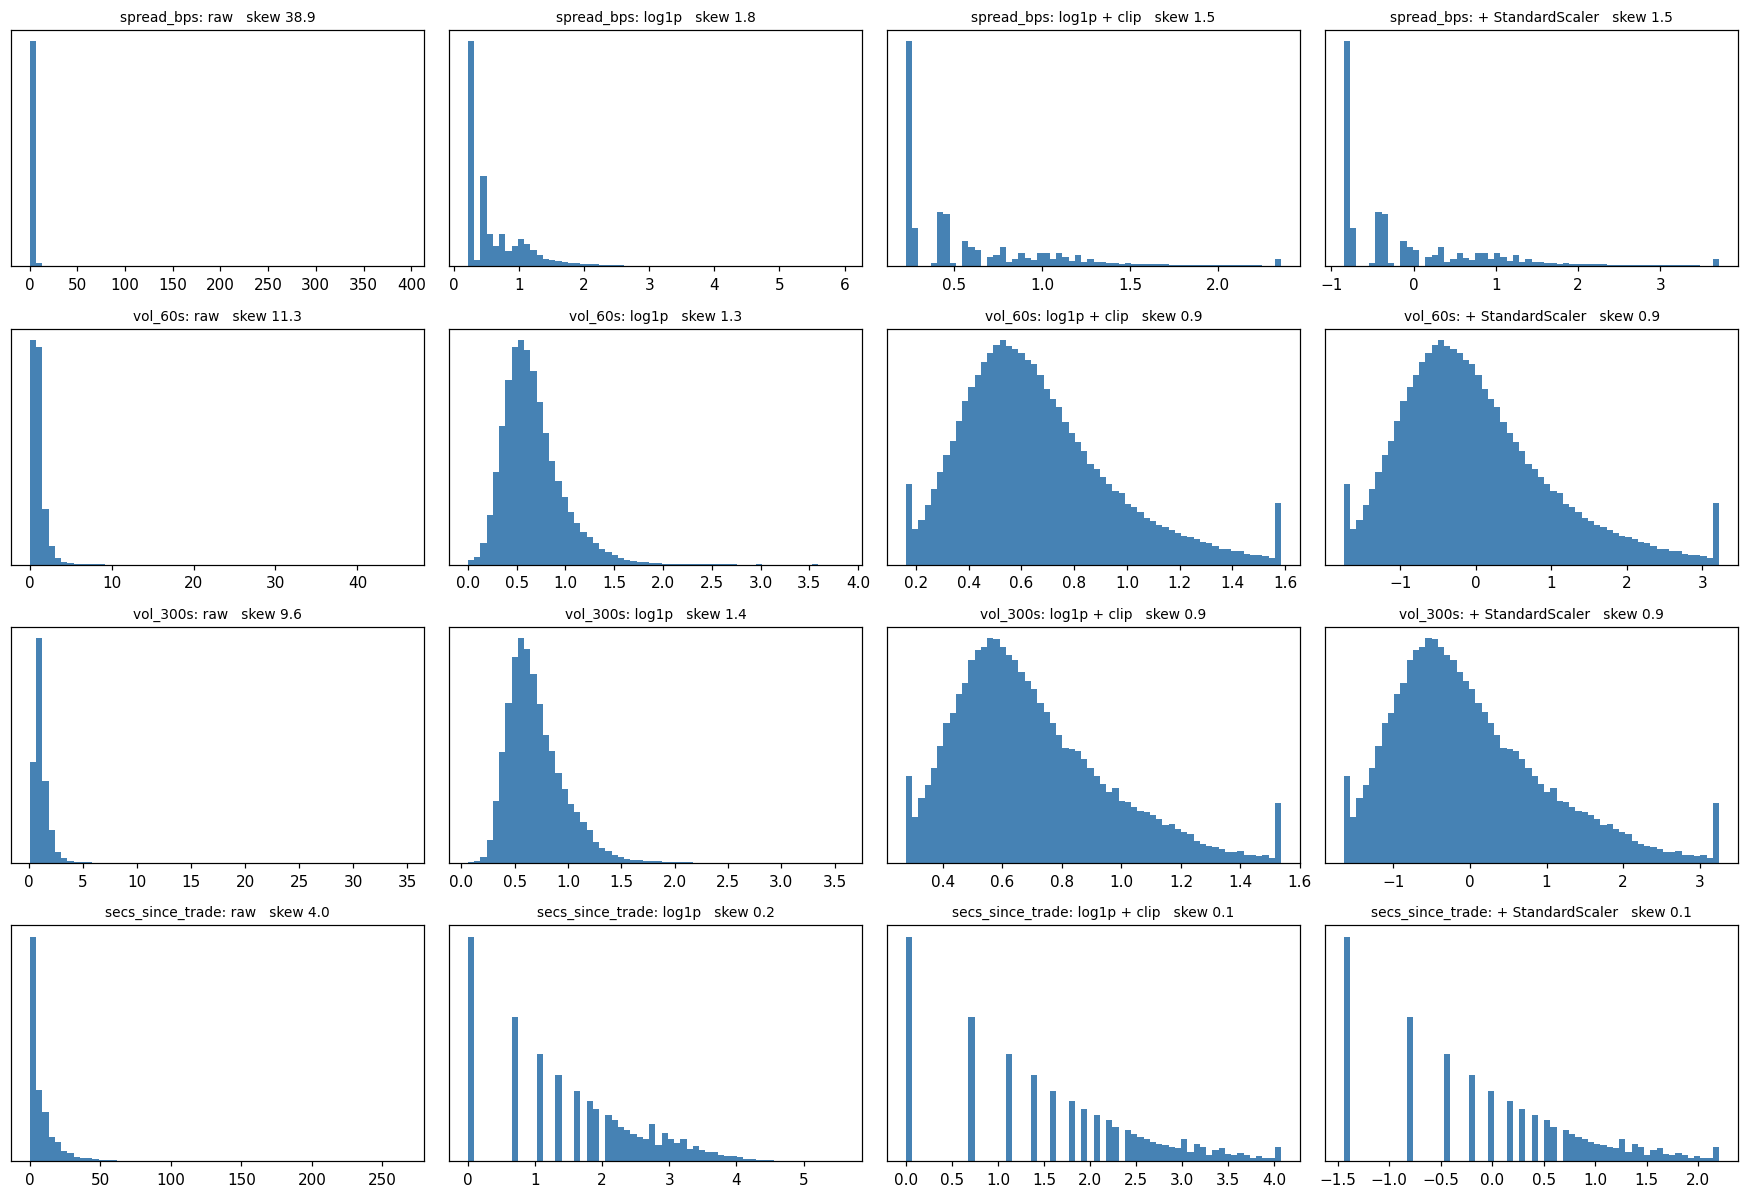

In [14]:
# Before / after for the four long-tailed features
cols = ["spread_bps", "vol_60s", "vol_300s", "secs_since_trade"]
fig, axes = plt.subplots(len(cols), 4, figsize=(16, 11))
for i, col in enumerate(cols):
    raw = train[col].dropna()
    logged = np.log1p(raw)
    lo, hi = logged.quantile([0.01, 0.99])
    clipped = logged.clip(lo, hi)
    scaled = (clipped - clipped.mean()) / clipped.std()
    for j, (x, name) in enumerate([(raw, "raw"), (logged, "log1p"), (clipped, "log1p + clip"), (scaled, "+ StandardScaler")]):
        axes[i, j].hist(x, bins=60, color="steelblue")
        axes[i, j].set_title(f"{col}: {name}   skew {x.skew():.1f}", fontsize=9)
        axes[i, j].set_yticks([])
plt.tight_layout()
plt.show()

| Feature | Raw skew | log1p | + clip |
|---|---|---|---|
| `spread_bps` | +38.9 | +1.8 | +1.5 |
| `vol_60s` | +11.3 | +1.3 | +0.9 |
| `vol_300s` | +9.6 | +1.4 | +0.9 |
| `secs_since_trade` | +4.0 | +0.2 | +0.1 |

`log1p` does most of the work. `spread_bps` stays lumpy because spreads come in fixed price steps; `secs_since_trade` shows separate bars because it counts whole seconds. Both are fine. The goal is to tame extremes, not to make anything perfectly normal. The last column has the same shape as the third: **scaling doesn't fix skew**.

Tree models (Random Forest, LightGBM) don't need any of this; logistic regression and the neural network do.

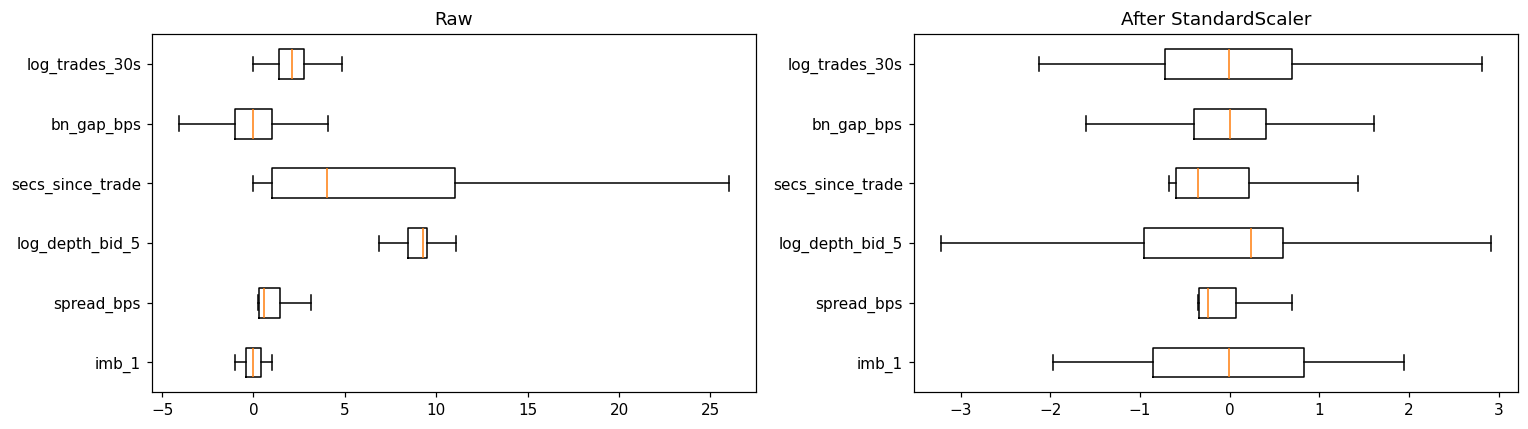

In [15]:
# Why scaling: raw ranges vs after StandardScaler
cols = ["imb_1", "spread_bps", "log_depth_bid_5", "secs_since_trade", "bn_gap_bps", "log_trades_30s"]
raw = train[cols].dropna()
scaled = pd.DataFrame(StandardScaler().fit_transform(raw), columns=cols)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].boxplot([raw[c] for c in cols], vert=False, showfliers=False, tick_labels=cols)
axes[0].set_title("Raw")
axes[1].boxplot([scaled[c] for c in cols], vert=False, showfliers=False, tick_labels=cols)
axes[1].set_title("After StandardScaler")
plt.tight_layout()
plt.show()

Raw features live on very different ranges (`log_depth_bid_5` around 9, `imb_1` between −1 and 1, `secs_since_trade` up to 26+ inside the box). After scaling they are comparable.

## 10. Feature vs target

In [16]:
# Average of each feature for DOWN / FLAT / UP rows
data = train.dropna(subset=[TARGET])
y = data[TARGET].astype(int)
means = data.groupby(y)[["imb_1", "ofi_5s", "bn_gap_bps", "vol_60s", "log_trades_30s", "spread_bps"]].mean()
means.index = ["DOWN", "FLAT", "UP"]
means.round(3)

,imb_1,ofi_5s,bn_gap_bps,vol_60s,log_trades_30s,spread_bps
DOWN,-0.081,-0.249,-0.242,1.147,2.185,1.367
FLAT,0.007,0.027,0.010,0.843,1.897,0.904
UP,0.091,0.234,0.186,1.148,2.182,1.383


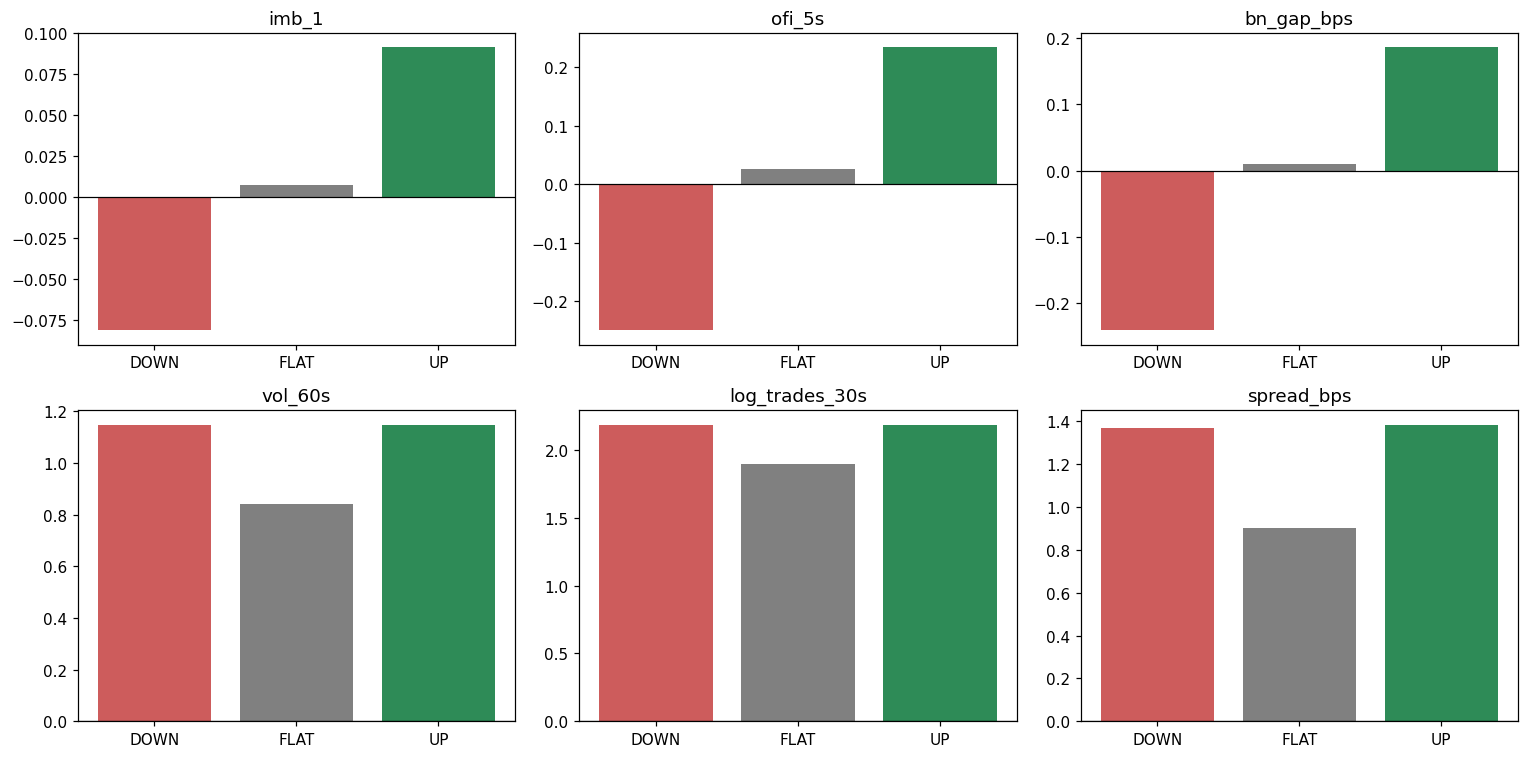

In [17]:
# Bar chart of the group means
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.flat, means.columns):
    ax.bar(means.index, means[col], color=["indianred", "grey", "seagreen"])
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_title(col)
plt.tight_layout()
plt.show()

### Hypothesis tests

**t-test (UP vs DOWN)**
- **H0:** the mean of the feature is the same before UP moves and before DOWN moves.
- **H1:** the means differ.

**ANOVA (all 3 classes)**
- **H0:** the mean is the same for DOWN, FLAT and UP.
- **H1:** at least one class mean differs.

alpha = 0.05

In [18]:
# t-test (UP vs DOWN) and one-way ANOVA (DOWN / FLAT / UP)
alpha = 0.05
for col in means.columns:
    d = data.dropna(subset=[col])
    yy = d[TARGET].astype(int)
    t_stat, t_p = stats.ttest_ind(d.loc[yy == 1, col], d.loc[yy == -1, col], equal_var=False)
    f_stat, f_p = stats.f_oneway(*[d.loc[yy == k, col] for k in (-1, 0, 1)])
    print(f"{col:15s}  t-test p = {t_p:.1e} ({'reject' if t_p < alpha else 'keep'} H0)   "
          f"ANOVA p = {f_p:.1e} ({'reject' if f_p < alpha else 'keep'} H0)")

imb_1            t-test p = 0.0e+00 (reject H0)   ANOVA p = 0.0e+00 (reject H0)


ofi_5s           t-test p = 0.0e+00 (reject H0)   ANOVA p = 0.0e+00 (reject H0)


bn_gap_bps       t-test p = 1.3e-225 (reject H0)   ANOVA p = 2.9e-282 (reject H0)


vol_60s          t-test p = 8.1e-01 (keep H0)   ANOVA p = 0.0e+00 (reject H0)


log_trades_30s   t-test p = 4.8e-01 (keep H0)   ANOVA p = 0.0e+00 (reject H0)


spread_bps       t-test p = 2.8e-01 (keep H0)   ANOVA p = 0.0e+00 (reject H0)


The features split into **two kinds**:

- **Direction features** (`imb_1`, `ofi_5s`, `bn_gap_bps`): positive before UP, negative before DOWN, and the t-test rejects H0. They tell us **which way** the price will move. For example, the book is buyer-heavy (`imb_1` ≈ +0.09) before UP moves and seller-heavy (≈ −0.08) before DOWN moves.
- **Activity features** (`vol_60s`, `log_trades_30s`, `spread_bps`): UP and DOWN look the same (t-test keeps H0), but FLAT is lower (ANOVA rejects H0). They tell us **whether** the price will move at all.

A good model needs both kinds.

## 11. Correlation

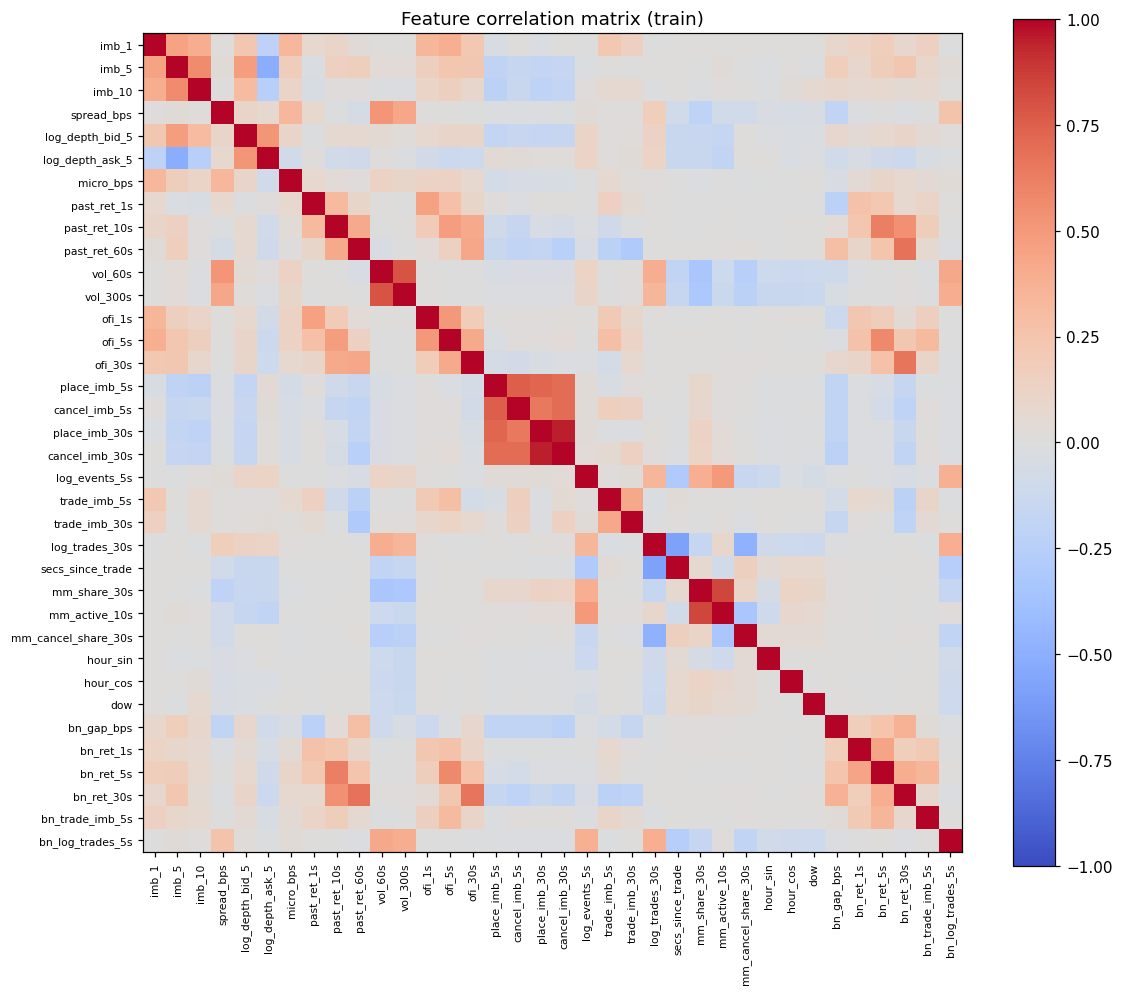

In [19]:
# Correlation matrix of all features
feats = [c for c in FEATURES if c != "modify_share_30s"]   # constant column dropped
corr = data[feats].corr()

plt.figure(figsize=(12, 10))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(feats)), feats, rotation=90, fontsize=7)
plt.yticks(range(len(feats)), feats, fontsize=7)
plt.title("Feature correlation matrix (train)")
plt.show()

In [20]:
# Pairs of features that are highly correlated (|r| > 0.8)
pairs = [(a, b, round(corr.loc[a, b], 3))
         for i, a in enumerate(feats) for b in feats[i + 1:]
         if abs(corr.loc[a, b]) > 0.8]
pairs

[('place_imb_30s', 'cancel_imb_30s', np.float64(0.948)),
 ('mm_share_30s', 'mm_active_10s', np.float64(0.838))]

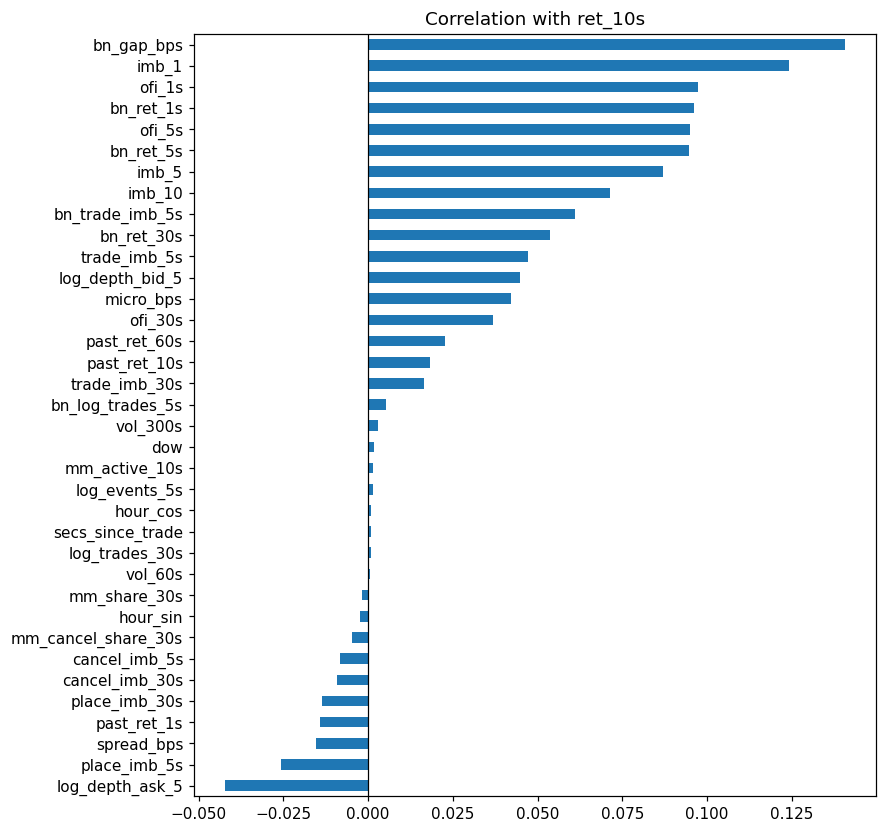

In [21]:
# Correlation of each feature with the 10-second return (the target as a number)
data[feats].corrwith(data["ret_10s"]).sort_values().plot(kind="barh", figsize=(8, 9),
                                                          title="Correlation with ret_10s")
plt.axvline(0, color="black", linewidth=0.8)
plt.show()

- The blocks along the diagonal of the heatmap are the feature groups (order flow, trades, Binance…).
- **Redundant pairs (|r| > 0.8):** `place_imb_30s` and `cancel_imb_30s` (r = 0.95), and `mm_share_30s` and `mm_active_10s` (0.84). Each pair carries almost the same information, so we keep one of each. (`place_imb_5s` / `cancel_imb_5s` are close behind at about 0.75.)
- **Strongest relationship with the return:** `bn_gap_bps` (0.14), `imb_1` (0.12), `ofi_1s` and `bn_ret_1s` (about 0.10). These look small, but for 10-second price moves even 0.1 is a meaningful signal.

## 12. Feature selection

In [22]:
# SelectKBest with the ANOVA F-score (all 3 classes)
X = data[feats].fillna(data[feats].median())
skb = SelectKBest(f_classif, k=10).fit(X, y)
kbest = pd.Series(skb.scores_, index=feats).sort_values(ascending=False)

# Ranking by |t| for UP vs DOWN only
t_rank = pd.Series({c: abs(stats.ttest_ind(X.loc[y == 1, c], X.loc[y == -1, c], equal_var=False).statistic)
                    for c in feats}).sort_values(ascending=False)

pd.DataFrame({"SelectKBest top 10": kbest.index[:10], "UP vs DOWN top 10": t_rank.index[:10]})

,SelectKBest top 10,UP vs DOWN top 10
0,vol_300s,imb_1
1,vol_60s,ofi_5s
2,bn_log_trades_5s,ofi_1s
3,imb_1,imb_5
4,log_trades_30s,imb_10
5,ofi_5s,bn_ret_1s
6,ofi_1s,bn_ret_5s
7,log_events_5s,bn_trade_imb_5s
8,secs_since_trade,bn_gap_bps
9,imb_5,log_depth_ask_5


### Why correlation and SelectKBest disagree

Look back at the bar charts in section 10:

| | DOWN | FLAT | UP |
|---|---|---|---|
| `imb_1` | −0.08 | 0.01 | +0.09 |
| `vol_60s` | 1.15 | 0.84 | 1.15 |

- `imb_1` goes **low → middle → high**: it tells us **which way** the price moves. Correlation finds this kind of feature.
- `vol_60s` is **the same for UP and DOWN** and only lower for FLAT: it tells us **whether** the price moves, not which way. Correlation can't see that (≈ 0), but SelectKBest can, because FLAT's average is clearly different.

In one sentence: *some features predict the direction, others predict whether there will be a move at all; correlation only finds the first kind, SelectKBest finds both.*

The two rankings disagree, and that is the lesson:
- `SelectKBest(f_classif)` scores all three classes together, so it rewards features that separate **FLAT** from the rest: the activity features (`vol_300s`, `vol_60s`, trade counts).
- Ranking by UP vs DOWN rewards the **direction** features (`imb_1`, `ofi_*`, `bn_ret_*`).

So we don't blindly take SelectKBest's top 10; we keep both kinds. `dow` comes in just outside the top 10 (11th), but August has only 4–5 of each weekday, so it is most likely picking up individual days rather than a real weekly pattern. We leave it out.

## 13. Train / validation / test split

A random `train_test_split(test_size=0.2, random_state=42)` would put rows from the same minute in both train and test. The model would effectively see the answers and look far better than it really is. Instead we split **by time**, the way the model would be used in real life: learn from the past, predict the future.

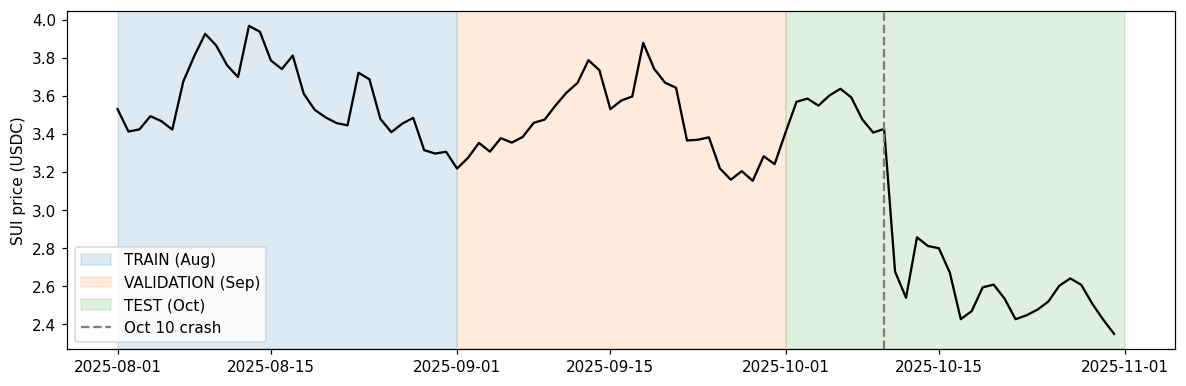

In [23]:
# Daily median mid-price with the three periods marked
def daily_mid(start, end):
    out = []
    for day in pd.date_range(start, end, inclusive="left"):
        d = day.strftime("%Y-%m-%d")
        mid = pd.read_parquet(DATA / "labels" / "pool=SUI_USDC" / f"date={d}.parquet", columns=["mid"]).mid
        out.append((day, mid.median()))
    return pd.DataFrame(out, columns=["day", "mid"])

prices = daily_mid("2025-08-01", "2025-11-01")
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(prices.day, prices.mid, color="black")
for start, end, color, name in [("2025-08-01", "2025-09-01", "tab:blue", "TRAIN (Aug)"),
                                ("2025-09-01", "2025-10-01", "tab:orange", "VALIDATION (Sep)"),
                                ("2025-10-01", "2025-11-01", "tab:green", "TEST (Oct)")]:
    ax.axvspan(pd.Timestamp(start), pd.Timestamp(end), color=color, alpha=0.15, label=name)
ax.axvline(pd.Timestamp("2025-10-10"), color="grey", linestyle="--", label="Oct 10 crash")
ax.set_ylabel("SUI price (USDC)")
ax.legend(loc="lower left")
plt.show()

- **Train:** August, used to fit thresholds, scalers and models.
- **Validation:** September, used to compare models and tune hyperparameters (`GridSearchCV` with `TimeSeriesSplit`, not normal k-fold).
- **Test:** October, used once at the end. It includes the **Oct 10 crash**, so test results are reported before and after the crash separately.

## 14. Summary and decisions

| Finding | Decision for modeling |
|---|---|
| Classes balanced in Aug, FLAT 49% in Sep | Use **macro F1** + confusion matrix, not accuracy alone |
| `mm_*` missing on Aug 1 (first day) | Drop **Aug 1** (also the warm-up day); fill remaining gaps with the training median |
| `modify_share_30s` is always 0 | Drop it |
| Long right tails (`spread_bps`, `vol_*`, `secs_since_trade`) | `log1p`, then clip at the 1st/99th percentile (train cutoffs) |
| IQR flags up to 44% of rows on spiky features | Don't delete rows; clip instead |
| No feature is normal (Shapiro-Wilk) | Fine for logistic regression; transform + scale instead |
| Very different ranges | `StandardScaler` for logistic regression and the neural network (fit on train only) |
| Direction vs activity features | Keep both kinds |
| `place_imb_30s` ≈ `cancel_imb_30s` (0.95), `mm_share_30s` ≈ `mm_active_10s` (0.84) | Keep one of each pair |
| `dow` looks important, but only 4–5 of each weekday | Leave it out |
| Time-series data | Split by time: Aug train / Sep validation / Oct test |

**Next notebook:** baselines (the imbalance rule and the Binance gap rule) and the first models (logistic regression, then Random Forest / LightGBM), all inside a scikit-learn `Pipeline` so every preprocessing step is learned from training data only.